Pokémon JSON Setup
--------------------------

Run your python code to crawl the Pokémon web site but pull down all 807 Pokémon into the __pokeapi__ table in your personal PostgreSQL server.  Then work through this notebook to read data from your personal PostgreSQL server.  Here is some sample JSON that comes back from the API: https://pokeapi.co/api/v2/pokemon/42 - you can look at this JSON to figure out the schema of the JSON.


In [31]:
# https://www.pg4e.com/code/ipynb/04-pokejson.ipynb
# %% Imports and warning filter
import warnings

import psycopg2
import pandas as pd

# suppress only the pandas warning about direct psycopg2 connections
warnings.filterwarnings(
    "ignore",
    message=r"pandas only supports SQLAlchemy connectable.*",
    category=UserWarning,
)

In [32]:
# %% Connect to your personal PostgreSQL database
# the password file lets Validate connect without an interactive prompt
conn = psycopg2.connect(
    host="pg.pg4e.com",
    port=5432,
    user="pg4e_da795b0640",
    dbname="pg4e_da795b0640",
    passfile="/voc/work/week4/.pgpass_pokejson",
    connect_timeout=5,
)

In [33]:
# %% Check that the loader saved all 807 Pokémon
sql = "SELECT count(*) FROM pokeapi;"
df = pd.read_sql_query(sql, conn)
assert df['count'][0] == 807

In [34]:
# %% Display the row count
df.head()

,count
0,807


In [35]:
# %% Extract names and weights for a 10-row preview
# ->> extracts a JSON field as text. ::integer converts it to a number
sql = "SELECT body->>'name' AS name, (body->'weight')::int AS weight FROM pokeapi LIMIT 10;"
df = pd.read_sql_query(sql, conn)
df.head()

,name,weight
0,bulbasaur,69
1,ivysaur,130
2,venusaur,1000
3,charmander,85
4,charmeleon,190


<Axes: >

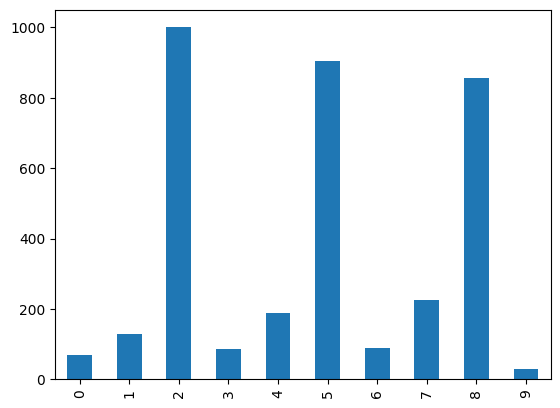

In [36]:
# %% Plot the preview weights
df['weight'].plot(kind='bar')

<Axes: title={'center': 'weight'}, xlabel='name'>

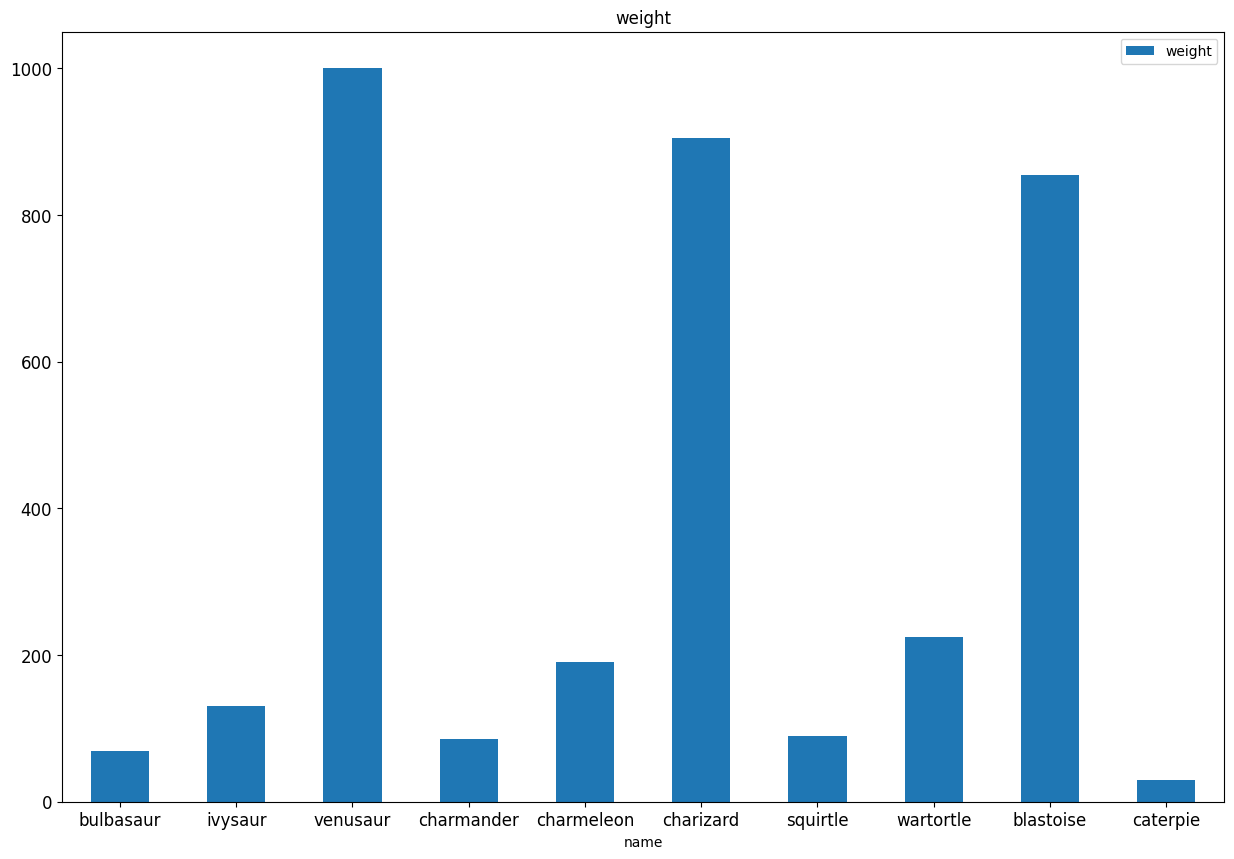

In [37]:
# https://stackoverflow.com/questions/38683709/python-pandas-how-to-set-dataframe-column-value-as-x-axis-labels
# %% Use Pokémon names as the bar labels
df.set_index('name').plot.bar(rot=0, title='weight', figsize=(15,10), fontsize=12)

In [38]:
# %% Extract heights and weights for a 10-row preview
sql = "SELECT (body->>'height')::int AS height, (body->'weight')::int AS weight FROM pokeapi LIMIT 10;"
df = pd.read_sql_query(sql, conn)
df.head()

,height,weight
0,7,69
1,10,130
2,20,1000
3,6,85
4,11,190


<Axes: xlabel='height', ylabel='weight'>

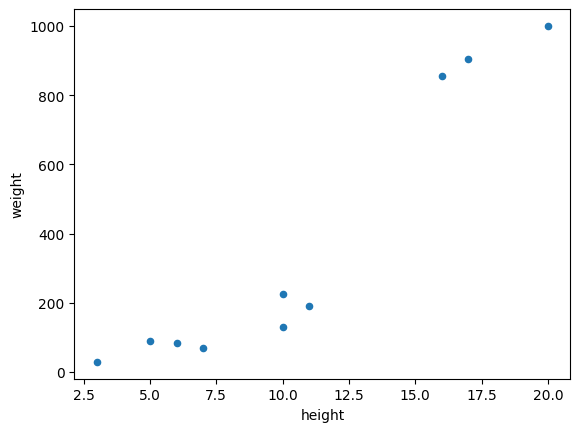

In [39]:
# https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.plot.scatter.html
# %% Compare height and weight in the preview
df.plot.scatter(x='height', y='weight')

In [40]:
# Write a query to return four columns
# id - The id of the pokemon
# exp - The base_experience value from the json body converted to an integer
# height - The height value from the json body converted to an integer
# weight - The weight value from the json body converted to an integer
# Return all the rows of data (i.e. no limit)
# Sort the returned rows by the id of the pokemon

# %% Extract the four required fields for all 807 Pokémon
# Use the Pokémon ID from the JSON and sort numerically by that ID
### BEGIN SOLUTION
sql = """
SELECT
    (body->>'id')::integer AS id,
    (body->>'base_experience')::integer AS exp,
    (body->>'height')::integer AS height,
    (body->>'weight')::integer AS weight
FROM pokeapi
ORDER BY id;
"""
### END SOLUTION

In [41]:
# %% Load the full result and preview the first five rows
df = pd.read_sql_query(sql, conn)
df.head()

,id,exp,height,weight
0,1,64,7,69
1,2,142,10,130
2,3,236,20,1000
3,4,62,6,85
4,5,142,11,190


In [42]:
# %% Run the notebook's checks
# count() counts non-null experience values
assert df['exp'].count() == 807

assert df['exp'][0] == 64
assert df['height'][0] == 7
assert df['weight'][0] == 69

### BEGIN HIDDEN TESTS
assert df['exp'][4] == 142
assert df['height'][4] == 11
assert df['weight'][4] == 190
### END HIDDEN TESTS

<Axes: xlabel='height', ylabel='weight'>

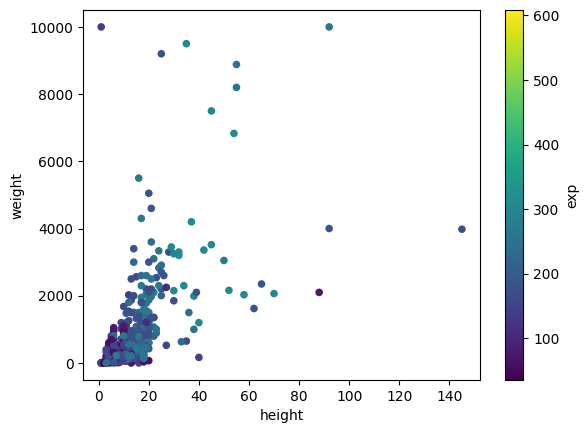

In [43]:
# %% Plot all Pokémon by height and weight, colored by base experience
df.plot.scatter(x='height', y='weight', c='exp', colormap='viridis')